In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [ ]:
df=pd.read_csv("fitness_tracker.csv")

In [ ]:
df.head(5)

,ID,Workout Duration (mins),Calories Burned,Step Count,Heart Rate
0,FT0001,69,356.178169,11146,73
1,FT0002,79,717.966682,16173,138
2,FT0003,85,229.367368,1232,97
3,FT0004,118,944.678742,13318,130
4,FT0005,56,811.475560,15984,74


In [ ]:
df.isnull().sum()

,0
ID,0
Workout Duration (mins),0
Calories Burned,0
Step Count,0
Heart Rate,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(500, 5)

In [ ]:
df.drop(columns=['ID'],inplace=True) #drop within the same dataset

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
#unify scale among all features
ss = StandardScaler()
x_scaled = ss.fit_transform(df)

In [ ]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)

# **Isolation Forest**

In [ ]:
from sklearn.ensemble import IsolationForest
isf = IsolationForest(contamination=0.05, random_state=42)

In [ ]:
df['IF_Anomaly'] = isf.fit_predict(x_scaled)

In [ ]:
df['IF_Anomaly'] = df['IF_Anomaly'].map({1: 0, -1: 1})

In [ ]:
print(df['IF_Anomaly'].value_counts()) #number of anomalies isf detected

IF_Anomaly
0    475
1     25
Name: count, dtype: int64


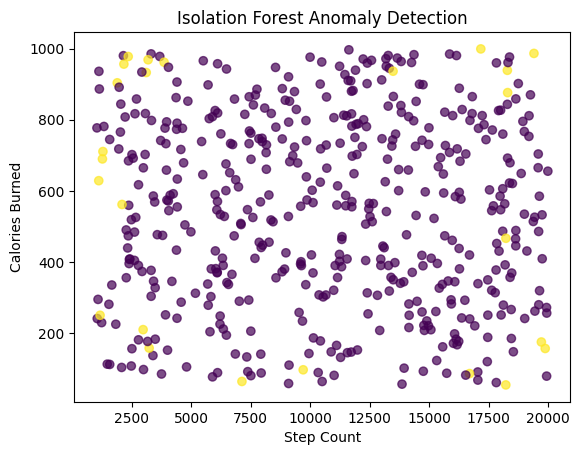

In [ ]:
plt.scatter(
    df['Step Count'],
    df['Calories Burned'],
    c=df['IF_Anomaly'],
    alpha=0.7
)

plt.xlabel('Step Count')
plt.ylabel('Calories Burned')
plt.title('Isolation Forest Anomaly Detection')
plt.show()

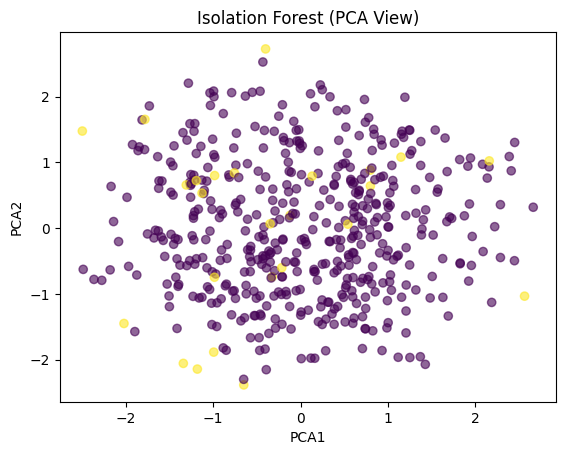

In [ ]:
plt.scatter(x_pca[:, 0], x_pca[:, 1],
            c=df['IF_Anomaly'], alpha=0.6)

plt.title("Isolation Forest (PCA View)")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.show()

## **KMeans**

In [ ]:
from sklearn.cluster import KMeans

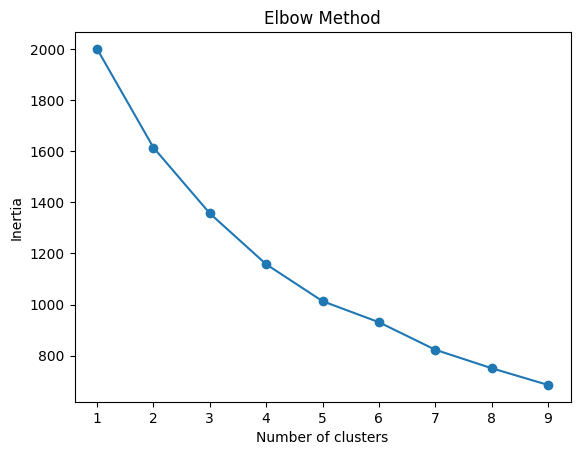

In [ ]:
#Optimal number of clusters
inertia = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, random_state=42, n_init=5)
    km.fit(x_scaled)
    inertia.append(km.inertia_)

plt.plot(range(1,10), inertia, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(x_scaled)

In [ ]:
distances = kmeans.transform(x_scaled).min(axis=1)
threshold = np.percentile(distances, 95)
df['KMeans_Anomaly'] = np.where(distances > threshold, 1, 0)

In [ ]:
df['KMeans_Anomaly'].value_counts()

,count
KMeans_Anomaly,
0,475
1,25


In [ ]:
cluster_anomalies = df.groupby('Cluster')['KMeans_Anomaly'].sum() #check how much each cluster holds anomaly points
print(cluster_anomalies)

Cluster
0     6
1    12
2     7
Name: KMeans_Anomaly, dtype: int64


In [ ]:
centroids=kmeans.cluster_centers_
centroids_pca = pca.transform(centroids)

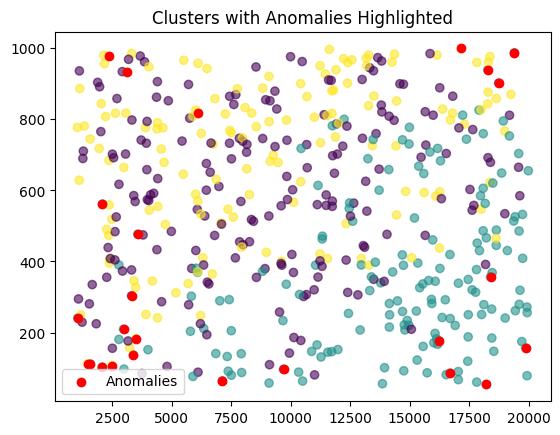

In [ ]:
plt.scatter(
    df['Step Count'],
    df['Calories Burned'],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.6
)

plt.scatter(
    df[df['KMeans_Anomaly'] == 1]['Step Count'],
    df[df['KMeans_Anomaly'] == 1]['Calories Burned'],
    color='red',
    label='Anomalies'
)

plt.title("Clusters with Anomalies Highlighted")
plt.legend()
plt.show()

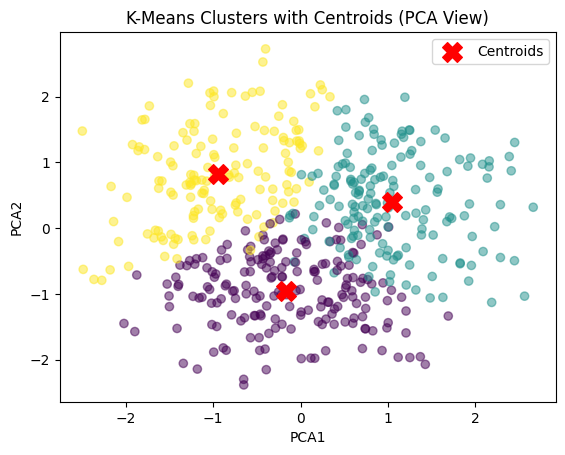

In [ ]:
plt.scatter(x_pca[:, 0], x_pca[:, 1],
            c=df['Cluster'],
            cmap='viridis',
            alpha=0.5)

plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            marker='X',
            s=200,
            color='red',
            label='Centroids')

plt.title("K-Means Clusters with Centroids (PCA View)")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend()
plt.show()

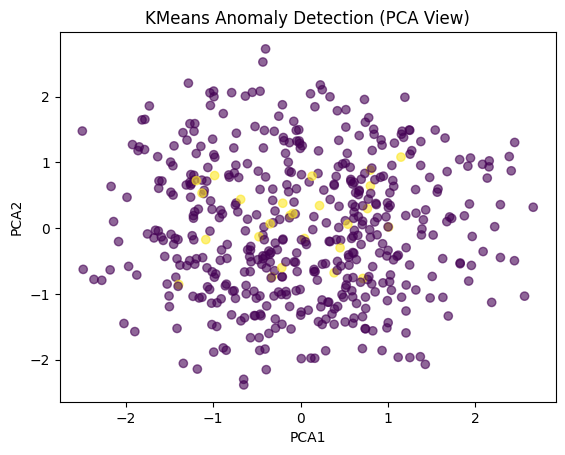

In [ ]:
plt.scatter(x_pca[:, 0], x_pca[:, 1],
            c=df['KMeans_Anomaly'], alpha=0.6)

plt.title("KMeans Anomaly Detection (PCA View)")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.show()

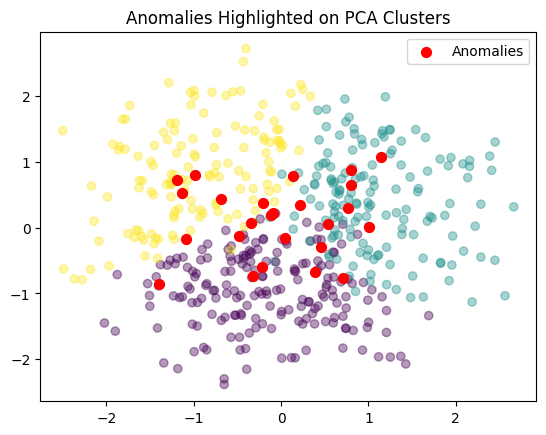

In [ ]:
normal = df['KMeans_Anomaly'] == 0
anomaly = df['KMeans_Anomaly'] == 1

plt.scatter(x_pca[normal, 0], x_pca[normal, 1],
            c=df['Cluster'][normal],
            cmap='viridis',
            alpha=0.4)

plt.scatter(x_pca[anomaly, 0], x_pca[anomaly, 1],
            color='red',
            label='Anomalies',
            s=50)

plt.legend()
plt.title("Anomalies Highlighted on PCA Clusters")
plt.show()

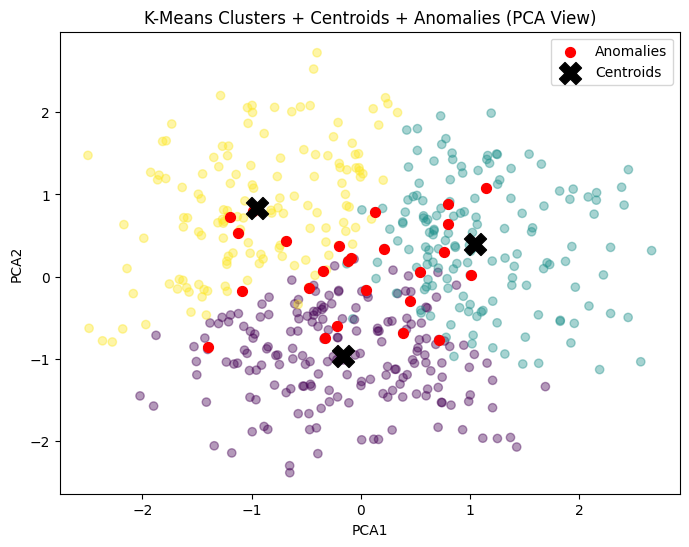

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(x_pca[:, 0], x_pca[:, 1],
            c=df['Cluster'],
            cmap='viridis',
            alpha=0.4)

plt.scatter(x_pca[df['KMeans_Anomaly'] == 1, 0],
            x_pca[df['KMeans_Anomaly'] == 1, 1],
            color='red',
            s=50,
            label='Anomalies')

plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            marker='X',
            s=250,
            color='black',
            label='Centroids')

plt.title("K-Means Clusters + Centroids + Anomalies (PCA View)")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend()
plt.show()

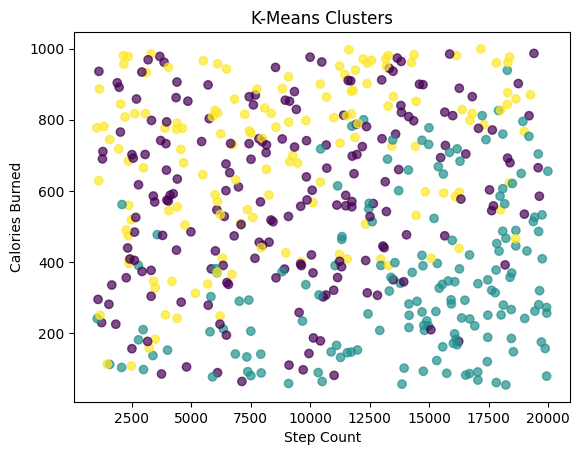

In [ ]:
plt.scatter(
    df['Step Count'],
    df['Calories Burned'],
    c=df['Cluster'],
    alpha=0.7
)

plt.xlabel('Step Count')
plt.ylabel('Calories Burned')
plt.title('K-Means Clusters')
plt.show()

OCSVM

In [ ]:
from sklearn.svm import OneClassSVM
svm = OneClassSVM(kernel='rbf', nu=0.05, gamma='scale')

In [ ]:
df['SVM_Anomaly'] = svm.fit_predict(x_scaled)
df['SVM_Anomaly'] = df['SVM_Anomaly'].map({1: 0, -1: 1})

In [ ]:
df['SVM_Anomaly'].value_counts()

,count
SVM_Anomaly,
0,475
1,25


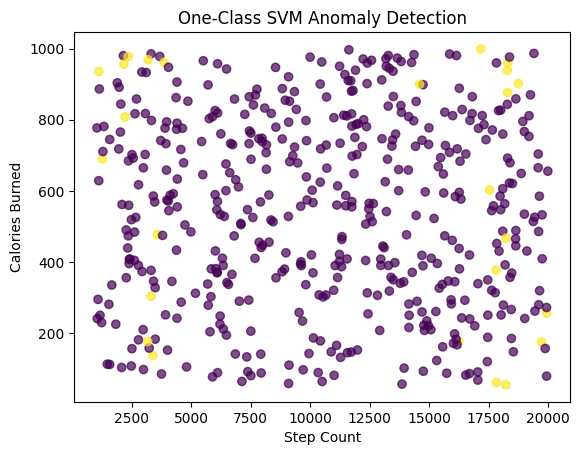

In [ ]:
plt.scatter(
    df['Step Count'],
    df['Calories Burned'],
    c=df['SVM_Anomaly'],
    alpha=0.7
)

plt.xlabel('Step Count')
plt.ylabel('Calories Burned')
plt.title('One-Class SVM Anomaly Detection')
plt.show()

In [ ]:
df['SVM_Anomaly'].value_counts()

,count
SVM_Anomaly,
0,475
1,25


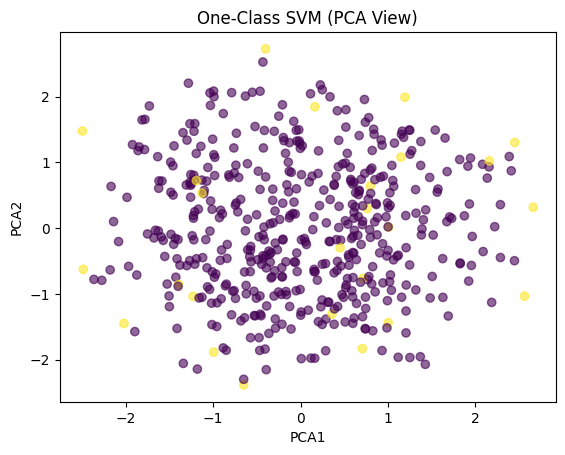

In [ ]:
plt.scatter(x_pca[:, 0], x_pca[:, 1],
            c=df['SVM_Anomaly'], alpha=0.6)

plt.title("One-Class SVM (PCA View)")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.show()

In [ ]:
kmeans_set = set(df[df['KMeans_Anomaly'] == 1].index)
svm_set = set(df[df['SVM_Anomaly'] == 1].index)
if_set = set(df[df['IF_Anomaly'] == 1].index)

In [ ]:
print("KMeans == SVM:", kmeans_set == svm_set)
print("KMeans == IF:", kmeans_set == if_set)
print("SVM == IF:", svm_set == if_set)

KMeans == SVM: False
KMeans == IF: False
SVM == IF: False


In [ ]:
from matplotlib_venn import venn3

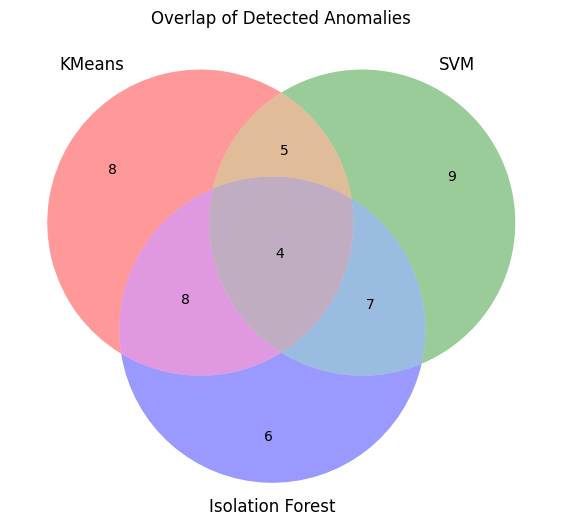

In [ ]:
plt.figure(figsize=(7,7))

venn3(
    [kmeans_set, svm_set, if_set],
    ('KMeans', 'SVM', 'Isolation Forest')
)

plt.title("Overlap of Detected Anomalies")
plt.show()